In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
df = pd.read_excel("Processed_Flipdata.xlsx")

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully
Dataset Shape: (541, 12)


,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [52]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (541, 12)

Column Names:
Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    str    
 2   Colour         541 non-null    str    
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    str    
 7   Front Camera   541 non-null    str    
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    str    
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory

In [53]:
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height,Prize
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201,16228.375231
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553,10793.588322
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000,920.000000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000,9290.000000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000,13499.000000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000,19280.000000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000,80999.000000


In [54]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [55]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [56]:
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize'],
      dtype='str')

### Data preprocessing

In [57]:
df = df.drop(columns=["Unnamed: 0"])

print("New Dataset Shape:", df.shape)
df.head()

New Dataset Shape: (541, 11)


,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


## Outliers Detection

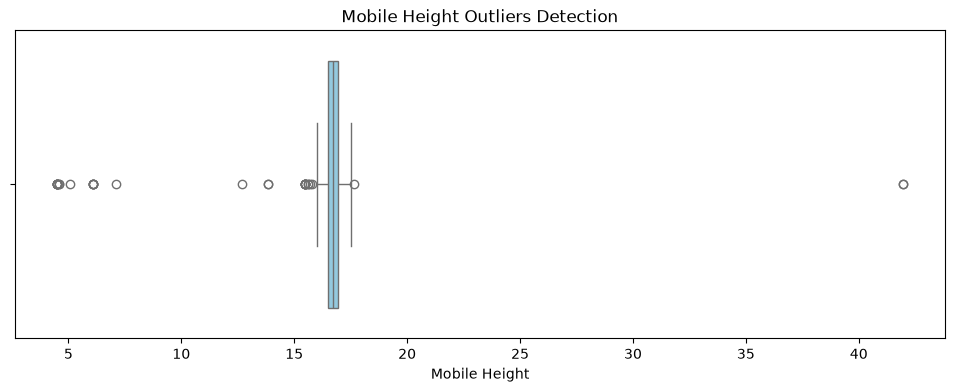

In [58]:
plt.figure(figsize=(12,4))
sns.boxplot(x=df["Mobile Height"], color="skyblue")
plt.title("Mobile Height Outliers Detection")
plt.xlabel("Mobile Height")
plt.show()

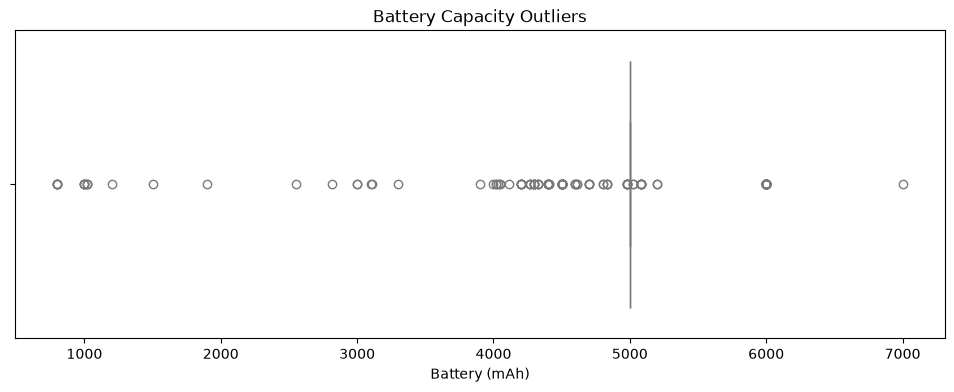

In [59]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df["Battery_"], color="lightblue")
plt.title("Battery Capacity Outliers")
plt.xlabel("Battery (mAh)")
plt.show()

The boxplot shows the distribution of battery capacity and helps identify potential outliers. 

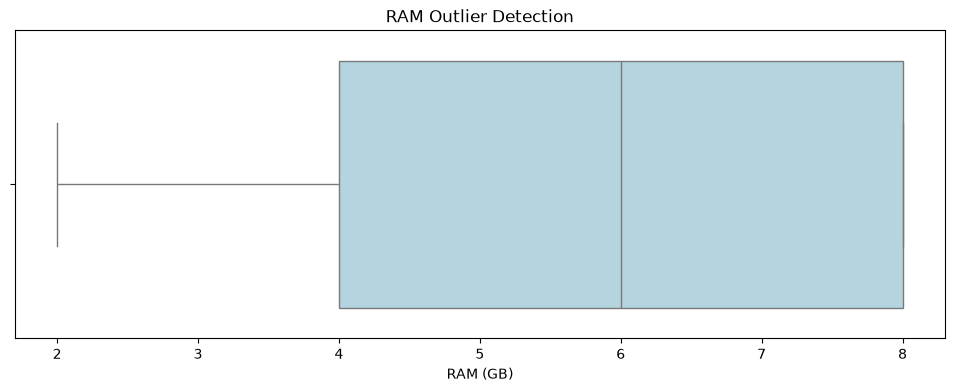

In [60]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df["RAM"], color="lightblue")
plt.title("RAM Outlier Detection")
plt.xlabel("RAM (GB)")
plt.show()

The boxplot shows the distribution of RAM in the dataset. It helps identify the spread of RAM values and detect potential outliers. The RAM values will be further considered during data analysis.

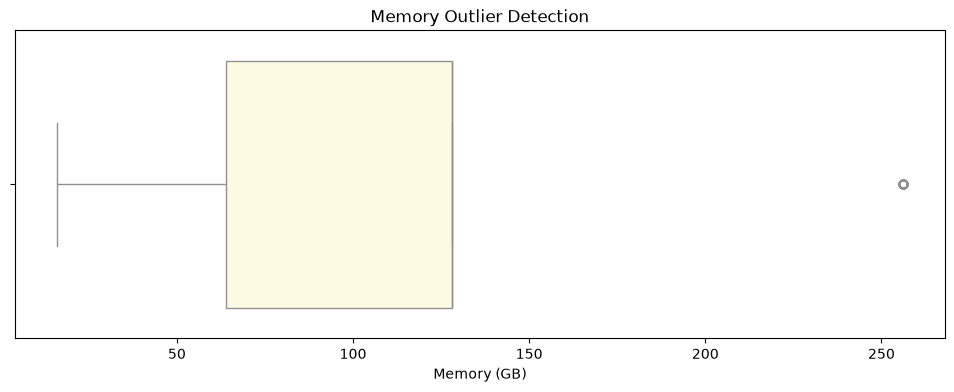

In [61]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df["Memory"], color="lightyellow")
plt.title("Memory Outlier Detection")
plt.xlabel("Memory (GB)")
plt.show()

The boxplot shows the distribution of memory values in the dataset. It helps identify the spread of memory values and detect potential outliers.

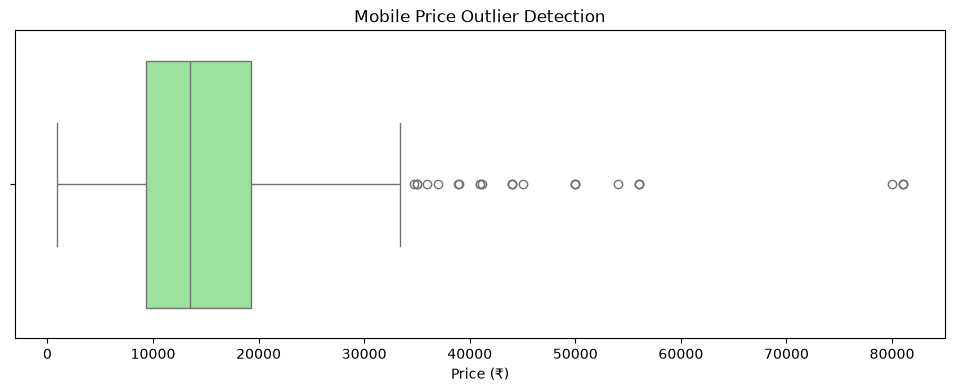

In [62]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df["Prize"], color="lightgreen")
plt.title("Mobile Price Outlier Detection")
plt.xlabel("Price (₹)")
plt.show()

The boxplot shows the distribution of mobile phone prices and helps identify potential outliers in the target variable.

### Outlier count

In [63]:
cols = ["Memory", "RAM", "Battery_", "Mobile Height", "Prize"]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    count = ((df[col] < Q1-1.5*IQR) | (df[col] > Q3+1.5*IQR)).sum()
    print(col, ":", count)

Memory : 55
RAM : 0
Battery_ : 152
Mobile Height : 33
Prize : 25


The IQR method identified potential outliers in Memory, Battery, Mobile Height, and Prize. No outliers were detected in RAM

### Check IQR values

In [64]:
for col in ["Memory", "RAM", "Battery_", "Mobile Height", "Prize"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    print(col, "Q1:", Q1, "Q3:", Q3, "IQR:", Q3-Q1)

Memory Q1: 64.0 Q3: 128.0 IQR: 64.0
RAM Q1: 4.0 Q3: 8.0 IQR: 4.0
Battery_ Q1: 5000.0 Q3: 5000.0 IQR: 0.0
Mobile Height Q1: 16.51 Q3: 16.94 IQR: 0.4299999999999997
Prize Q1: 9290.0 Q3: 19280.0 IQR: 9990.0


The IQR method was used to examine the distribution of numerical features and identify potential outliers. The analysis shows that Memory, Mobile Height, and Prize have some potential outliers, while RAM has none. Battery has an IQR of zero because its first and third quartiles are both 5000. Therefore, Battery values require further investigation before applying outlier treatment.

In [65]:
print(df["Battery_"].value_counts().head(10))

Battery_
5000    389
6000     42
4500     26
5080      6
4980      6
800       5
4400      5
4300      5
4200      5
1000      4
Name: count, dtype: int64


The frequency of battery capacity values is examined to understand their distribution. This helps identify repeated values and investigate why the IQR is zero.

### Outlier Treatment (Memory)

In [66]:
Q1 = df["Memory"].quantile(0.25)
Q3 = df["Memory"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["Memory"] = df["Memory"].clip(lower, upper)
print("Memory Outlier Treatment Done")
print(df["Memory"].describe())

Memory Outlier Treatment Done
count    541.000000
mean     107.297597
std       53.085066
min       16.000000
25%       64.000000
50%      128.000000
75%      128.000000
max      224.000000
Name: Memory, dtype: float64


The IQR method was applied to handle potential outliers in the Memory column. Values below 0 GB and above 224 GB were capped within the calculated limits. This process reduced the effect of extreme values while preserving all 541 records in the dataset.

In [67]:
print("RAM Outlier Count:", df["RAM"].between(2, 14).sum())
print("Total RAM Records:", len(df))

RAM Outlier Count: 541
Total RAM Records: 541


No potential outliers were detected in the RAM column using the IQR method. Therefore, no outlier treatment was required for RAM.

## Ram outlier check

In [68]:
Q1 = df["RAM"].quantile(0.25)
Q3 = df["RAM"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

count = ((df["RAM"] < lower) | (df["RAM"] > upper)).sum()
print("RAM Outliers:", count)

RAM Outliers: 0


RAM contains no outliers according to the IQR method.

### Mobile Height Outlier Treatment

In [69]:
Q1 = df["Mobile Height"].quantile(0.25)
Q3 = df["Mobile Height"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["Mobile Height"] = df["Mobile Height"].clip(lower, upper)
print("Mobile Height Outlier Treatment Done")
print(df["Mobile Height"].describe())

Mobile Height Outlier Treatment Done
count    541.000000
mean      16.675869
std        0.316393
min       15.865000
25%       16.510000
50%       16.710000
75%       16.940000
max       17.585000
Name: Mobile Height, dtype: float64


Potential outliers in the Mobile Height column were treated using the IQR capping method. All 541 records were retained, and the maximum value was capped at the upper IQR limit.

### Prize Outlier Treatment

In [70]:
Q1 = df["Prize"].quantile(0.25)
Q3 = df["Prize"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["Prize"] = df["Prize"].clip(lower, upper)
print("Prize Outlier Treatment Done")
print(df["Prize"].describe())

Prize Outlier Treatment Done
count      541.000000
mean     15499.798521
std       8234.745675
min        920.000000
25%       9290.000000
50%      13499.000000
75%      19280.000000
max      34265.000000
Name: Prize, dtype: float64


Potential outliers in the Prize column were treated using the IQR capping method. All 541 records were retained, and the extreme values were capped within the IQR limits.

### Final Outlier Treatment Check

In [71]:
cols = ["Memory", "RAM", "Battery_", "Mobile Height", "Prize"]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, "Remaining Outliers:", count)

Memory Remaining Outliers: 0
RAM Remaining Outliers: 0
Battery_ Remaining Outliers: 152
Mobile Height Remaining Outliers: 0
Prize Remaining Outliers: 0


Outlier treatment was completed for Memory, RAM, Mobile Height, and Prize. Battery_ still shows 152 potential outliers because its IQR is zero. These values were retained because they require further investigation before treatment.

### Feature Engineering

In [72]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())

Dataset Shape: (541, 11)

Data Types:
Model                str
Colour               str
Memory             int64
RAM                int64
Battery_           int64
Rear Camera          str
Front Camera         str
AI Lens            int64
Mobile Height    float64
Processor_           str
Prize              int64
dtype: object

Categorical Columns:
['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor_']


C:\Users\hp\AppData\Local\Temp\ipykernel_6184\3407174101.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


In [73]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print(col, ":", df[col].nunique(), "Unique Values")

Model : 187 Unique Values
Colour : 275 Unique Values
Rear Camera : 14 Unique Values
Front Camera : 13 Unique Values
Processor_ : 123 Unique Values


C:\Users\hp\AppData\Local\Temp\ipykernel_6184\3917840905.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


### Categorical Values Check

In [74]:
cat_cols = df.select_dtypes(include=["str"]).columns

for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts().head(5))


 Model
Model
realme C55               9
REDMI Note 12 Pro 5G     9
vivo Y16                 9
SAMSUNG Galaxy A14 5G    9
Infinix HOT 30i          8
Name: count, dtype: int64

 Colour
Colour
Yellow         12
Royal Blue      8
Power Black     8
Black           8
Cool Blue       7
Name: count, dtype: int64

 Rear Camera
Rear Camera
50MP    260
13MP     63
64MP     62
8MP      52
48MP     31
Name: count, dtype: int64

 Front Camera
Front Camera
16MP    164
5MP     135
8MP     129
13MP     49
32MP     22
Name: count, dtype: int64

 Processor_
Processor_
Qualcomm Snapdragon 680       33
Unisoc T612                   21
Mediatek Helio A22            19
Mediatek Dimensity 1080       18
Qualcomm Snapdragon 695 5G    17
Name: count, dtype: int64


### Camera Values Check

In [75]:
print("Rear Camera Values:")
print(sorted(df["Rear Camera"].unique()))

print("\nFront Camera Values:")
print(sorted(df["Front Camera"].unique()))

Rear Camera Values:
['0MP', '108MP', '12MP', '13MP', '16MP', '200MP', '2MP', '32MP', '40MP', '48MP', '50MP', '5MP', '64MP', '8MP']

Front Camera Values:
['0MP', '10MP', '12MP', '13MP', '16MP', '20MP', '2MP', '32MP', '44MP', '50MP', '5MP', '60MP', '8MP']


The most frequent categories in each categorical column were identified. Camera values will be examined before converting them into numerical features.

### Check 0MP Values

In [76]:
print("Rear Camera 0MP:", (df["Rear Camera"] == "0MP").sum())

print("Front Camera 0MP:", (df["Front Camera"] == "0MP").sum())

Rear Camera 0MP: 10
Front Camera 0MP: 16


Unique values in the Rear Camera and Front Camera columns were examined. The frequency of 0MP values is being checked before feature conversion.

In [77]:
df["Rear Camera MP"] = df["Rear Camera"].str.replace("MP", "").astype(int)
df["Front Camera MP"] = df["Front Camera"].str.replace("MP", "").astype(int)

print(df[["Rear Camera", "Rear Camera MP",
          "Front Camera", "Front Camera MP"]].head())

print("\nNew Dataset Shape:", df.shape)

  Rear Camera  Rear Camera MP Front Camera  Front Camera MP
0        13MP              13          5MP                5
1        13MP              13          5MP                5
2        50MP              50         16MP               16
3         8MP               8          5MP                5
4        50MP              50          5MP                5

New Dataset Shape: (541, 13)


Rear Camera and Front Camera values were converted from text format to numerical megapixel values. The original columns were retained for reference.

### Processor Values Check

In [78]:
print("Total Unique Processors:", df["Processor_"].nunique())

print("\nTop 10 Processors:")
print(df["Processor_"].value_counts().head(10))

Total Unique Processors: 123

Top 10 Processors:
Processor_
Qualcomm Snapdragon 680       33
Unisoc T612                   21
Mediatek Helio A22            19
Mediatek Dimensity 1080       18
Qualcomm Snapdragon 695 5G    17
Mediatek Helio P35            16
Mediatek Helio G85            10
Mediatek Helio G99            10
Helio G88                     10
Mediatek Dimensity 810        10
Name: count, dtype: int64


### Processor Brand Extraction

In [79]:
df["Processor Brand"] = df["Processor_"].str.split().str[0]

print(df["Processor Brand"].value_counts())

Processor Brand
Mediatek             163
Qualcomm             116
Unisoc                54
MediaTek              52
Dimensity             28
Helio                 27
Exynos                18
Snapdragon            12
SEC                    9
G37                    8
SC6531E                7
Spreadtrum             6
Google                 5
Octa                   5
Meditek                4
SC9863A                3
Tensor                 3
Octa-core(EXYNOS)      3
ios                    3
2GHz,                  2
Oxygen                 2
0                      1
UNISOC                 1
MT6260A                1
MTK6261D               1
Android                1
snapdragon             1
QualcommÂ®             1
MTK                    1
IOS                    1
Octa-core              1
6                      1
Name: count, dtype: int64


Processor categories were analyzed, and the first word of each processor name was extracted to create a new Processor Brand feature.

### Processor Brand Cleaning

In [80]:
def get_brand(x):
    x = str(x).lower()

    if "qualcomm" in x or "snapdragon" in x:
        return "Qualcomm"
    elif "mediatek" in x or "meditek" in x or "mtk" in x:
        return "MediaTek"
    elif "unisoc" in x or "spreadtrum" in x:
        return "Unisoc"
    elif "exynos" in x:
        return "Samsung"
    elif "google" in x or "tensor" in x:
        return "Google"
    else:
        return "Other"

df["Processor Brand"] = df["Processor_"].apply(get_brand)

print(df["Processor Brand"].value_counts())

Processor Brand
MediaTek    221
Qualcomm    130
Other        91
Unisoc       61
Samsung      30
Google        8
Name: count, dtype: int64


### Brand Distribution

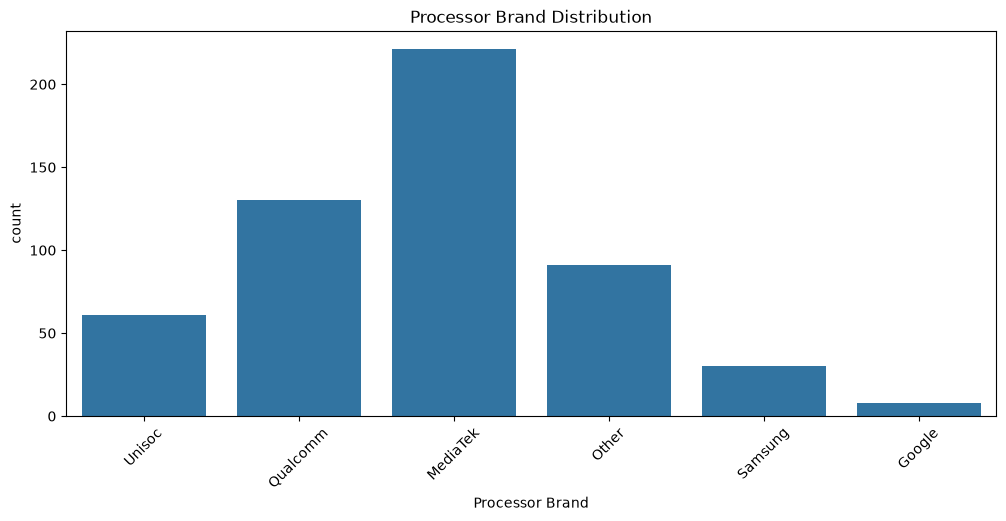

In [81]:
plt.figure(figsize=(12,5))
sns.countplot(data=df, x="Processor Brand")
plt.title("Processor Brand Distribution")
plt.xticks(rotation=45)
plt.show()

The chart shows that MediaTek processors are the most common in the dataset, followed by Qualcomm and Unisoc. Google processors have the lowest representation.

In [82]:
print(df[["Rear Camera MP", "Front Camera MP", "Processor Brand"]].head())
print("\nDataset Shape:", df.shape)

   Rear Camera MP  Front Camera MP Processor Brand
0              13                5          Unisoc
1              13                5          Unisoc
2              50               16        Qualcomm
3               8                5        MediaTek
4              50                5           Other

Dataset Shape: (541, 14)


New features were successfully created for Rear Camera MP, Front Camera MP, and Processor Brand. The dataset now contains 541 rows and 14 columns.

## Columns Check

In [84]:
cat_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()
print(cat_cols)

['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor_', 'Processor Brand']


### One-Hot Encoding

In [85]:
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print("New Dataset Shape:", df.shape)
print(df.head())

New Dataset Shape: (541, 620)
   Memory  RAM  Battery_  AI Lens  Mobile Height  Prize  Rear Camera MP  \
0      64    4      6000        1          16.76   7299              13   
1      64    4      6000        1          16.76   7299              13   
2     128    8      5000        0          16.64  11999              50   
3      32    2      5000        0          16.56   5649               8   
4     128    8      5000        1          16.76   8999              50   

   Front Camera MP  Model_APPLE iPhone 12  Model_APPLE iPhone 14 Plus  ...  \
0                5                  False                       False  ...   
1                5                  False                       False  ...   
2               16                  False                       False  ...   
3                5                  False                       False  ...   
4                5                  False                       False  ...   

   Processor__Unisoc T616  Processor__Unisoc Tiger

Categorical variables were converted into numerical format using One-Hot Encoding.

### Extraction using Correlation

In [86]:
correlation = df.corr(numeric_only=True)["Prize"]

top_features = correlation.drop("Prize").abs().sort_values(ascending=False).head(15)

print(top_features)

Memory                                0.692721
Front Camera MP                       0.651642
RAM                                   0.651490
Rear Camera MP                        0.538359
Front Camera_5MP                      0.490267
Front Camera_16MP                     0.358981
Front Camera_32MP                     0.357925
Rear Camera_8MP                       0.337393
Processor Brand_Unisoc                0.324449
Rear Camera_64MP                      0.303816
Processor Brand_Qualcomm              0.302335
Rear Camera_13MP                      0.282774
Rear Camera_12MP                      0.258675
Rear Camera_200MP                     0.248546
Processor__Mediatek Dimensity 1080    0.244268
Name: Prize, dtype: float64


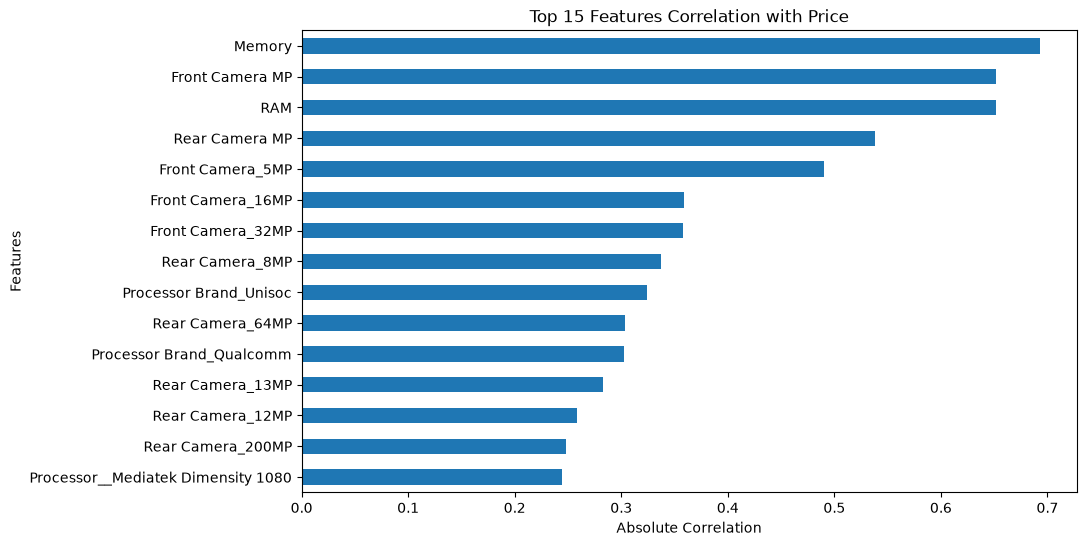

In [87]:
plt.figure(figsize=(10, 6))

top_features.sort_values().plot(kind="barh")

plt.title("Top 15 Features Correlation with Price")
plt.xlabel("Absolute Correlation")
plt.ylabel("Features")
plt.show()

he correlation graph visualizes the top 15 features associated with mobile phone prices.

### Select Important Features

In [88]:
selected_features = top_features.head(10).index.tolist()

print("Selected Features:")
print(selected_features)

Selected Features:
['Memory', 'Front Camera MP', 'RAM', 'Rear Camera MP', 'Front Camera_5MP', 'Front Camera_16MP', 'Front Camera_32MP', 'Rear Camera_8MP', 'Processor Brand_Unisoc', 'Rear Camera_64MP']


The top 10 features were selected based on their correlation with the target variable, Prize.

### Model building

### Separate Input (X) and Target (y)

In [91]:
X = df[selected_features]
y = df["Prize"]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (541, 10)
Target Shape: (541,)


he selected features were assigned to the input variable X, and Prize was assigned as the target variable y.

### Train-Test Split

In [92]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (432, 10)
Testing Data: (109, 10)


The dataset was divided into 80% training data and 20% testing data to build and evaluate the machine learning model.

### Linear Regression Model

In [93]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


### Price Prediction

In [95]:
y_pred = model.predict(X_test)
result = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": y_pred})
print(result.head(10))

   Actual Price  Predicted Price
0          8499     10262.893004
1          6299      6344.968960
2         19499     22814.373041
3         10999     14451.141000
4         12599     14400.374811
5         14499     16201.616303
6          9999      8609.710526
7         17999     16134.847124
8         29499     19737.330107
9          9790      8758.728079


The trained Linear Regression model was used to predict mobile phone prices on the testing dataset.

### Model Evaluation (MAE and RMSE)

In [96]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)

Mean Absolute Error: 2918.5752389979475
Root Mean Squared Error: 4313.74077019117


The Linear Regression model was evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).The Linear Regression model achieved an MAE of 2918.58 and an RMSE of 4313.74 on the testing dataset.

### Feature Importance Analysis

In [98]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

importance["Absolute Importance"] = importance["Coefficient"].abs()

importance = importance.sort_values(
    by="Absolute Importance", ascending=False
)

print(importance.head(10))

                  Feature  Coefficient  Absolute Importance
6       Front Camera_32MP  4949.556853          4949.556853
9        Rear Camera_64MP  2656.586966          2656.586966
7         Rear Camera_8MP  1292.103549          1292.103549
4        Front Camera_5MP -1077.109935          1077.109935
8  Processor Brand_Unisoc -1018.902656          1018.902656
2                     RAM   900.620746           900.620746
1         Front Camera MP   222.791650           222.791650
5       Front Camera_16MP   -47.860884            47.860884
0                  Memory    47.285574            47.285574
3          Rear Camera MP    30.032569            30.032569


Feature importance was analyzed using the absolute coefficients of the Linear Regression model to identify influential features.The feature importance analysis showed that Front Camera_32MP had the highest absolute coefficient, followed by Rear Camera_64MP and Rear Camera_8MP.

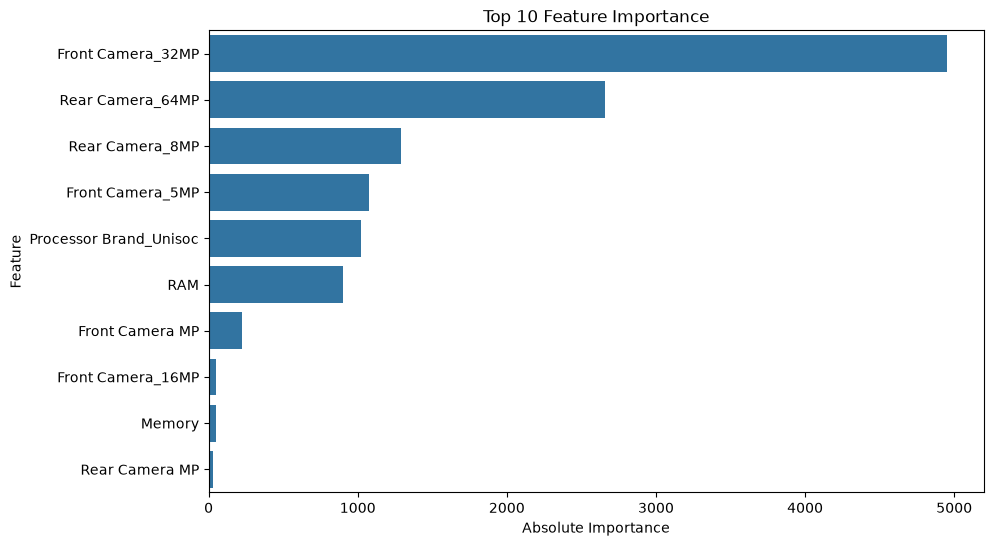

In [99]:
plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10),x="Absolute Importance", y="Feature")
plt.title("Top 10 Feature Importance")
plt.show()

The feature importance graph visually represents the top 10 features influencing the Linear Regression model's predictions.

### Feature Importance Graph

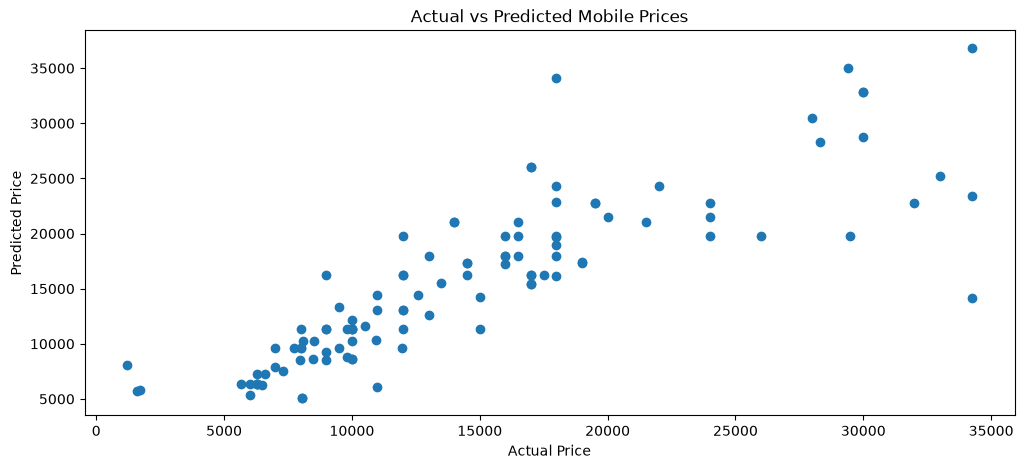

In [101]:
plt.figure(figsize=(12, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Mobile Prices")

plt.show()

The scatter plot compares actual mobile phone prices with predicted prices generated by the Linear Regression model.

### Project Recommendations

1. RAM and Memory should be considered important factors while deciding mobile phone prices.
2. Camera specifications may influence customer preferences and pricing decisions.
3. Processor brands should be considered when comparing mobile phone models.
4. Companies should analyze important product features before setting prices.
5. Machine Learning models can help estimate mobile phone prices and support pricing decisions.

### Project Conclusion

This project focused on feature extraction and price prediction for mobile phones. The dataset was explored, cleaned, and preprocessed. Categorical variables were converted into numerical format using One-Hot Encoding. Important features were identified through correlation analysis. A Linear Regression model was trained and evaluated using MAE and RMSE. Feature importance analysis was also performed to identify influential features. The project demonstrates how machine learning can help predict mobile phone prices and support pricing decisions.